In [ ]:
!pip install opencv-python numpy

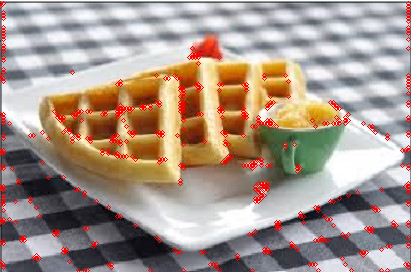

In [ ]:

import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Read the image
image = cv2.imread('/content/harris_corner_detection_image.jpg')

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Convert image to float
gray = np.float32(gray)

# Apply Harris Corner Detection
corners = cv2.cornerHarris(gray, 2, 3, 0.04)

# Dilate the corners
corners = cv2.dilate(corners, None)

# Draw red circles on detected corners
result = image.copy()

threshold = 0.01 * corners.max()

for y in range(0, image.shape[0], 3):
    for x in range(0, image.shape[1], 3):
        if corners[y, x] > threshold:
            cv2.circle(result, (x, y), 2, (0, 0, 255), 1)

# Save the result
cv2.imwrite('/content/image_after.png', result)

# Display the result
cv2_imshow(result)


In [ ]:

import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from IPython.display import display, Video
from google.colab import files

# Open the video
video = cv2.VideoCapture('/content/harris_corner_detection_image_V.mp4')

fps = video.get(cv2.CAP_PROP_FPS)
width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Create output video
output = cv2.VideoWriter(
    '/content/video_after.mp4',
    cv2.VideoWriter_fourcc(*'mp4v'),
    fps,
    (width, height)
)

while True:
    success, frame = video.read()

    if not success:
        break

    # Convert frame to grayscale
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray = np.float32(gray)

    # Apply Harris Corner Detection
    corners = cv2.cornerHarris(gray, 2, 3, 0.04)

    # Dilate the corners
    corners = cv2.dilate(corners, None)

    threshold = 0.01 * corners.max()

    result = frame.copy()

    # Draw circles on detected corners
    for y in range(0, height, 3):
        for x in range(0, width, 3):
            if corners[y, x] > threshold:
                cv2.circle(result, (x, y), 2, (0, 0, 255), 1)

    # Write processed frame
    output.write(result)

video.release()
output.release()

print("Video processing completed!")


Video processing completed!


In [ ]:
from google.colab import files

files.download('/content/image_after.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('/content/video_after.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>